# 01 · Keşifsel Analiz: Huni, Kanallar, Süre ve Performans

**Amaç:** Temizlenmiş CRM verisinden satış kararlarını etkileyen örüntüleri bulmak.

**Veri:** `pipeline/generate_raw.py` ile üretilen sentetik CRM dışa aktarımı, `pipeline/build_dataset.py` ile temizlendi.
Veri sentetik olduğu için örüntülerin bir kısmı üreticide tanımlıdır; buradaki amaç, bunları gerçek bir analistin
yapacağı şekilde **bulmak, ölçmek ve yanlış yorumlardan kaçınmaktır** (karıştırıcı etkenler, sansürleme, küçük örneklem).

Sorgular `analysis/sql/` altındaki DuckDB SQL dosyalarıdır; bu notebook onları çalıştırıp sonuçları yorumlar.

In [1]:
import sys
import warnings
from pathlib import Path
warnings.filterwarnings("ignore", message="Unable to import Axes3D")
sys.path.insert(0, str(Path.cwd().parent / "pipeline"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import analytics as a

plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "font.size": 10})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
STAGE_TR = {"Prospecting": "Potansiyel", "Qualification": "Nitelendirme", "Proposal": "Teklif", "Negotiation": "Müzakere", "Won": "Kazanıldı", "Lost": "Kaybedildi"}

data = a.load()
con = a.connect()
print(f"{len(data.deals):,} fırsat · {len(data.history):,} aşama geçişi · analiz tarihi {data.as_of.date()}")

6,613 fırsat · 22,035 aşama geçişi · analiz tarihi 2026-10-31


## 1. Huni: fırsatlar nerede kayboluyor?

Yalnızca **sonuçlanmış** fırsatlar kullanılır. Açık fırsatlar huniyi henüz tamamlamadığı için dahil edilseler
dönüşüm oranlarını olduğundan düşük gösterirdi.

In [2]:
funnel = a.run_sql(con, "01_huni.sql")
funnel

,stage,step,deals,share_of_leads,conversion_from_previous
0,Prospecting,1,5889,1.000,NaN
1,Qualification,2,4061,0.690,0.690
2,Proposal,3,2824,0.479,0.695
3,Negotiation,4,1810,0.307,0.641
4,Won,5,1342,0.228,0.741


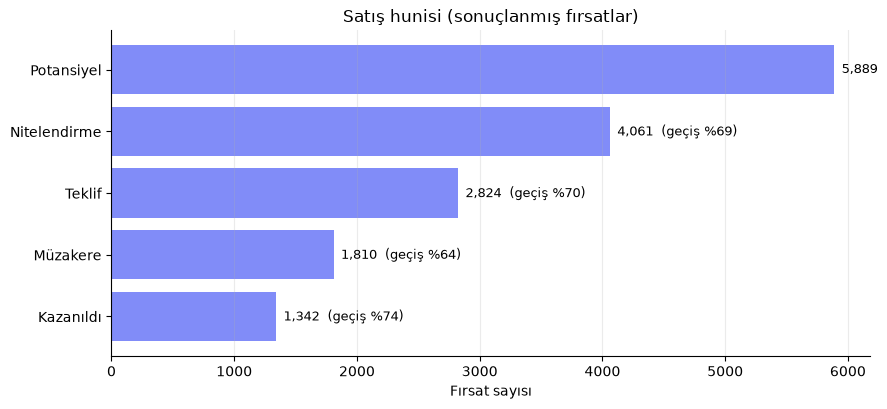

In [3]:
fig, ax = plt.subplots()
labels = funnel["stage"].map(STAGE_TR)
ax.barh(labels[::-1], funnel["deals"][::-1], color="#818cf8")
for y, (deals, conv) in enumerate(zip(funnel["deals"][::-1], funnel["conversion_from_previous"][::-1])):
    ax.text(deals + 60, y, f"{deals:,}" + ("" if pd.isna(conv) else f"  (geçiş %{conv*100:.0f})"), va="center", fontsize=9)
ax.set_title("Satış hunisi (sonuçlanmış fırsatlar)"); ax.set_xlabel("Fırsat sayısı"); ax.grid(axis="y", visible=False)
plt.tight_layout()

**Bulgu:** Baştan sona kazanma oranı yaklaşık %23. En düşük geçiş oranı **Teklif → Müzakere** adımında.
Kayıp nedenlerine bakınca bu aşamada fiyat ve rakip itirazları öne çıkıyor:

In [4]:
losses = a.run_sql(con, "05_kayip_nedenleri.sql")
losses.pivot_table(index="lost_at_stage", columns="reason", values="share_in_stage").loc[a.OPEN_STAGES].rename(index=STAGE_TR).round(2)

reason,Belirtilmedi,Bütçe yok,Fiyat,Rakip,Yanıt yok,Zamanlama,İhtiyaç yok
lost_at_stage,,,,,,,
Potansiyel,0.090,NaN,NaN,NaN,0.540,0.090,0.290
Nitelendirme,0.080,0.270,NaN,NaN,0.180,0.140,0.340
Teklif,0.080,0.160,0.360,0.270,NaN,0.130,NaN
Müzakere,0.070,0.070,0.420,0.300,NaN,0.130,NaN


Erken aşamalardaki kayıplar çoğunlukla *yanıt yok / ihtiyaç yok* (niteleme sorunu), geç aşamalardakiler *fiyat / rakip*
(değer anlatımı ve fiyatlandırma sorunu). "Belirtilmedi" sütunu, kayıp nedeni alanının veri kalitesi sorununu gösterir.

## 2. Kanallar: satış eforu nereye gitmeli?

In [5]:
sources = a.run_sql(con, "02_kanal_performansi.sql")
sources

,lead_source,deals,to_qualification,to_proposal,to_negotiation,win_rate,avg_won_value,revenue_per_deal,median_cycle_days
0,Referans,868,0.811,0.659,0.460,0.361,"6,140.000","2,165.000",26.000
1,İş Ortağı,804,0.760,0.561,0.366,0.286,"5,392.000","1,529.000",34.000
2,Bilinmiyor,292,0.699,0.476,0.315,0.219,"6,658.000","1,391.000",34.500
3,Web,1724,0.683,0.473,0.302,0.223,"6,096.000","1,337.000",32.000
4,Etkinlik,679,0.688,0.462,0.280,0.189,"5,279.000",980.000,32.000
5,Outbound,1522,0.590,0.350,0.206,0.146,"6,109.000",863.000,42.000


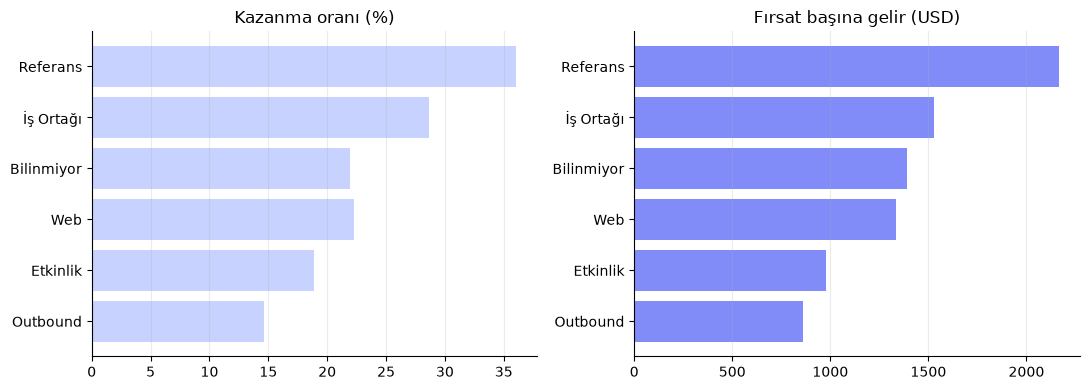

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
s = sources.sort_values("revenue_per_deal")
axes[0].barh(s["lead_source"], s["win_rate"] * 100, color="#c7d2fe"); axes[0].set_title("Kazanma oranı (%)")
axes[1].barh(s["lead_source"], s["revenue_per_deal"], color="#818cf8"); axes[1].set_title("Fırsat başına gelir (USD)")
for ax in axes: ax.grid(axis="y", visible=False)
plt.tight_layout()

**Bulgu:** Ortalama satış tutarı kanallar arasında benzer; fark kazanma oranından ve hızdan geliyor. Referans kaynaklı
fırsatlar Outbound'a göre fırsat başına yaklaşık 2,5 kat gelir getiriyor ve daha hızlı kapanıyor.

**Dikkat:** Bu fark tamamen kanalın "kalitesinden" mi geliyor? Kanal karışımı temsilciye göre değişiyorsa (bazı temsilciler
soğuk arama ağırlıklı çalışıyorsa) temsilci karşılaştırmaları da bundan etkilenir; 5. bölümde ele alınıyor.

## 3. Aşama süreleri ve "takılmış" fırsatlar

In [7]:
durations = a.run_sql(con, "03_asama_sureleri.sql")
durations.assign(stage=durations["stage"].map(STAGE_TR))

,stage,exits,median_days,p90_days,lost_share
0,Potansiyel,6367,5.000,14.000,0.287
1,Nitelendirme,4322,8.000,21.900,0.286
2,Teklif,2923,11.000,28.000,0.347
3,Müzakere,1810,9.000,23.000,0.259


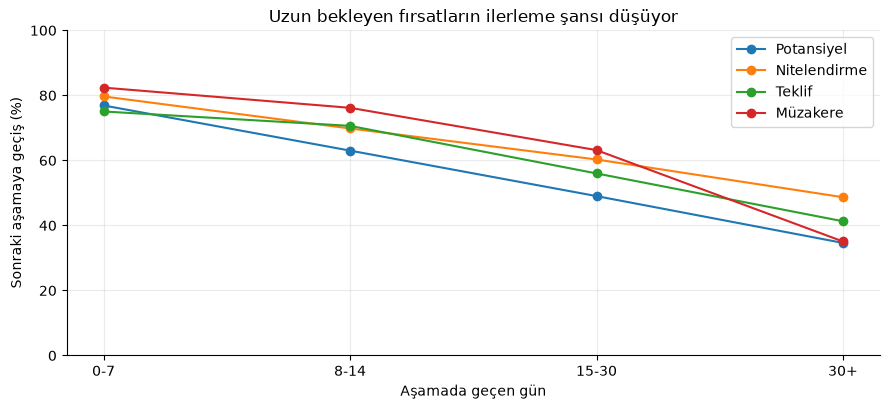

In [8]:
wait = a.run_sql(con, "04_bekleme_ve_ilerleme.sql")
fig, ax = plt.subplots()
for stage, part in wait.groupby("stage", sort=False):
    ax.plot(part["days_bucket"], part["advance_rate"] * 100, marker="o", label=STAGE_TR[stage])
ax.set_ylim(0, 100); ax.set_ylabel("Sonraki aşamaya geçiş (%)"); ax.set_xlabel("Aşamada geçen gün")
ax.set_title("Uzun bekleyen fırsatların ilerleme şansı düşüyor"); ax.legend()
plt.tight_layout()

Takılma eşiği keyfi seçilmedi: her aşamada, o aşamadan çıkan fırsatların **%90'ının** kaldığı süre (P90). Bu süreyi aşan
açık fırsat, geçmişteki fırsatların neredeyse hiçbirinin yaşamadığı bir beklemededir.

In [9]:
open_now = a.snapshot(data, data.as_of)
p90 = durations.set_index("stage")["p90_days"]
open_now["days_in_stage"] = np.expm1(open_now["log_days_in_stage"]).round()
open_now["stalled"] = open_now["days_in_stage"] > open_now["stage"].map(p90)
summary = open_now.groupby("stalled").agg(deals=("amount", "size"), pipeline=("amount", "sum"))
summary["pipeline_share"] = summary["pipeline"] / summary["pipeline"].sum()
summary

,deals,pipeline,pipeline_share
stalled,,,
False,304,"2,747,658.200",0.435
True,420,"3,570,169.900",0.565


**Bulgu:** Açık fırsatların yarıdan fazlası takılmış durumda ve pipeline tutarının da büyük kısmını oluşturuyor.
Bu fırsatlar standart "ağırlıklı pipeline" hesabına aktif fırsatlar gibi girer ve tahmini şişirir (bkz. notebook 03).

## 4. İndirim: daha çok indirim daha çok kazanç mı?

In [10]:
discount = a.run_sql(con, "07_indirim_etkisi.sql")
discount

,discount_band,band_order,deals,win_rate,realized_price_ratio,expected_revenue_ratio
0,%0-5,0.000,520,0.633,0.982,0.622
1,%5-10,1.000,521,0.735,0.926,0.681
2,%10-15,2.000,470,0.838,0.880,0.737
3,%15-20,3.000,229,0.799,0.833,0.665
4,%20+,4.000,70,0.757,0.774,0.586


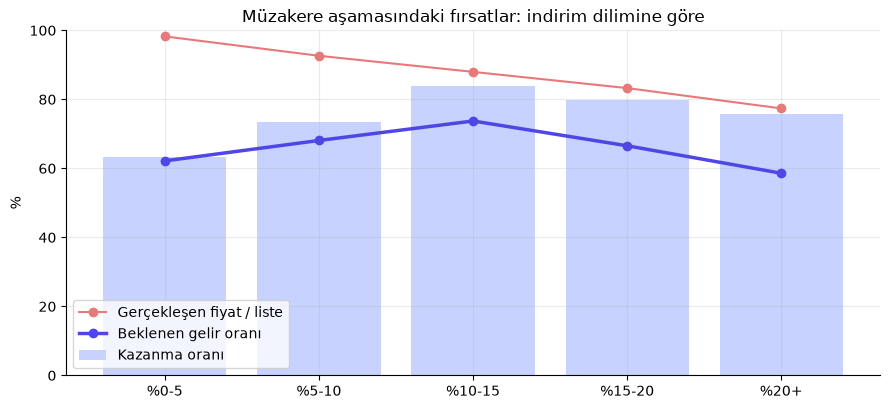

In [11]:
fig, ax = plt.subplots()
x = discount["discount_band"]
ax.bar(x, discount["win_rate"] * 100, color="#c7d2fe", label="Kazanma oranı")
ax.plot(x, discount["realized_price_ratio"] * 100, marker="o", color="#e87979", label="Gerçekleşen fiyat / liste")
ax.plot(x, discount["expected_revenue_ratio"] * 100, marker="o", color="#4f46e5", linewidth=2.5, label="Beklenen gelir oranı")
ax.set_ylim(0, 100); ax.set_ylabel("%"); ax.set_title("Müzakere aşamasındaki fırsatlar: indirim dilimine göre"); ax.legend(loc="lower left")
plt.tight_layout()

*Beklenen gelir oranı = kazanma oranı × gerçekleşen fiyat oranı*, yani liste fiyatının her dolarından elde edilen
ortalama gelir. Zirve orta dilimlerde; daha yüksek indirim kazanma oranını artırmadan fiyatı düşürüyor.

**Sınırlama:** Bu gözlemsel bir analiz. Yüksek indirim verilen fırsatlar zaten zor fırsatlar olabilir (ters nedensellik).
İndirim politikası değiştirilmeden önce kontrollü bir deneme (A/B) önerilir.

## 5. Temsilci performansı: ham oran neden yanıltır?

In [12]:
reps = a.run_sql(con, "06_temsilci_performansi.sql")
reps["rank_raw"] = reps["win_rate"].rank(ascending=False).astype(int)
reps["rank_adjusted"] = reps["mix_adjusted_index"].rank(ascending=False).astype(int)
reps[["sales_agent", "deals", "win_rate", "expected_won", "won", "mix_adjusted_index", "ci_low", "ci_high", "rank_raw", "rank_adjusted"]].head(12)

,sales_agent,deals,win_rate,expected_won,won,mix_adjusted_index,ci_low,ci_high,rank_raw,rank_adjusted
0,Kaan Çelik,213,0.338,38.452,72.000,1.872,0.278,0.404,4,1
1,Nazlı Tekin,213,0.343,49.117,73.000,1.486,0.282,0.409,3,2
2,Burak Polat,204,0.314,44.922,64.000,1.425,0.254,0.380,7,3
3,Esra Arslan,216,0.315,48.104,68.000,1.414,0.257,0.380,6,4
4,Ece Erdoğan,204,0.363,52.371,74.000,1.413,0.300,0.431,1,5
5,Deniz Ateş,203,0.355,53.903,72.000,1.336,0.292,0.423,2,6
6,Aslı Öztürk,198,0.323,50.906,64.000,1.257,0.262,0.391,5,7
7,Serkan Yıldız,254,0.291,59.418,74.000,1.245,0.239,0.350,8,8
8,İrem Aslan,211,0.289,49.554,61.000,1.231,0.232,0.354,9,9
9,Mehmet Çetin,226,0.212,40.227,48.000,1.193,0.164,0.270,13,10


Outbound payı ile korelasyon — ham oran: -0.31 · düzeltilmiş endeks: 0.05


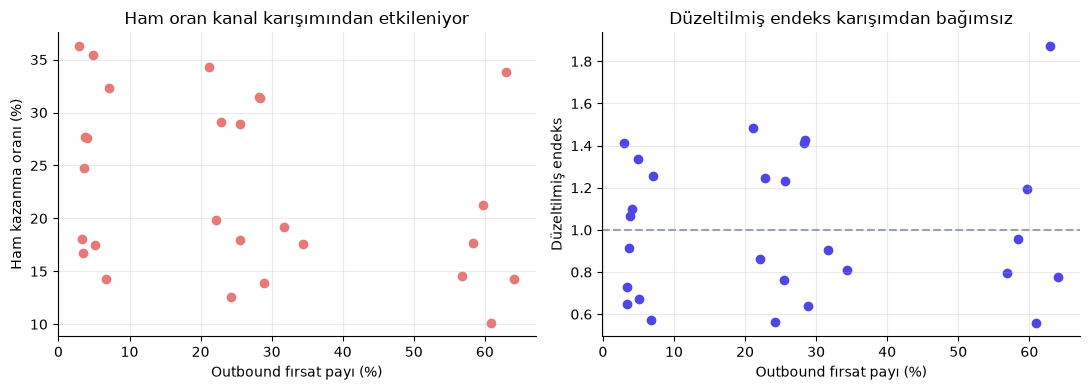

In [13]:
mix = (data.deals[data.deals["resolved"]].assign(source=lambda d: d["lead_source"].fillna("Bilinmiyor"))
       .pivot_table(index="sales_agent", columns="source", values="opportunity_id", aggfunc="count", fill_value=0))
mix = mix.div(mix.sum(axis=1), axis=0)
merged = reps.set_index("sales_agent").join(mix["Outbound"].rename("outbound_share"))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(merged["outbound_share"] * 100, merged["win_rate"] * 100, color="#e87979")
axes[0].set_xlabel("Outbound fırsat payı (%)"); axes[0].set_ylabel("Ham kazanma oranı (%)"); axes[0].set_title("Ham oran kanal karışımından etkileniyor")
axes[1].scatter(merged["outbound_share"] * 100, merged["mix_adjusted_index"], color="#4f46e5")
axes[1].axhline(1, color="#94a3b8", linestyle="--"); axes[1].set_xlabel("Outbound fırsat payı (%)"); axes[1].set_ylabel("Düzeltilmiş endeks"); axes[1].set_title("Düzeltilmiş endeks karışımdan bağımsız")
plt.tight_layout()
print("Outbound payı ile korelasyon — ham oran:", round(merged["outbound_share"].corr(merged["win_rate"]), 2), "· düzeltilmiş endeks:", round(merged["outbound_share"].corr(merged["mix_adjusted_index"]), 2))

**Bulgu:** Ham kazanma oranı, temsilcinin Outbound payıyla belirgin şekilde (orta düzeyde) negatif ilişkili; yani becerisinin
yanında çalıştığı kanalı da ölçüyor. Ürün × kanal karışımına göre düzeltilmiş endekste bu ilişki büyük ölçüde kayboluyor.

Wilson güven aralığı, hangi farkların istatistiksel olarak anlamlı olduğunu gösterir:

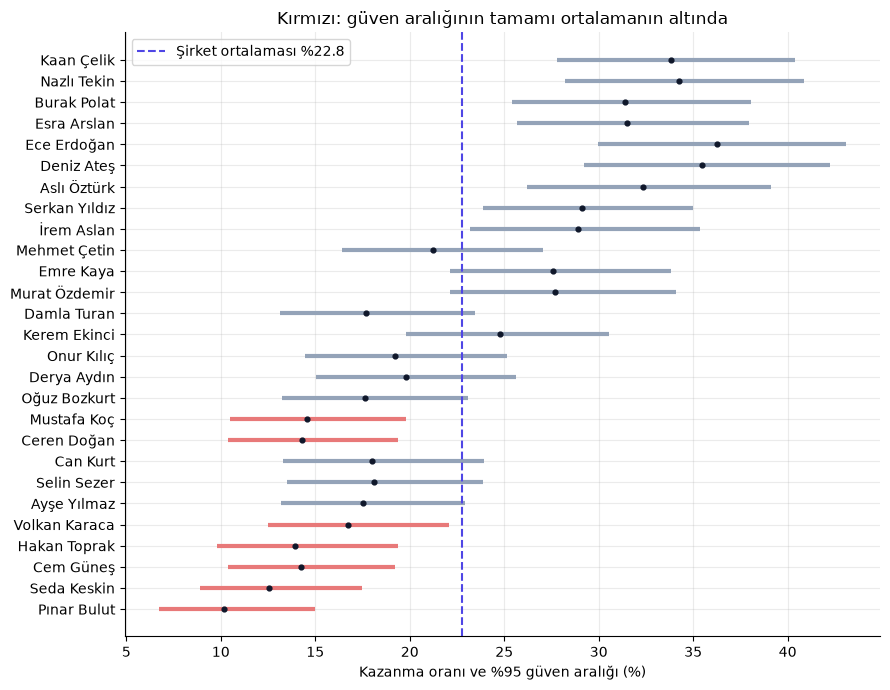

In [14]:
overall = data.deals.loc[data.deals["resolved"], "won"].mean()
r = reps.sort_values("mix_adjusted_index")
fig, ax = plt.subplots(figsize=(9, 7))
colors = ["#e87979" if hi < overall else "#94a3b8" for hi in r["ci_high"]]
ax.hlines(r["sales_agent"], r["ci_low"] * 100, r["ci_high"] * 100, color=colors, linewidth=3)
ax.scatter(r["win_rate"] * 100, r["sales_agent"], color="#0f172a", zorder=3, s=12)
ax.axvline(overall * 100, color="#4f46e5", linestyle="--", label=f"Şirket ortalaması %{overall*100:.1f}")
ax.set_xlabel("Kazanma oranı ve %95 güven aralığı (%)"); ax.set_title("Kırmızı: güven aralığının tamamı ortalamanın altında"); ax.legend()
plt.tight_layout()

## Özet

| Bulgu | Öneri |
|---|---|
| En zayıf huni adımı Teklif → Müzakere; kayıplar fiyat ve rakip kaynaklı | Teklif aşaması için değer anlatımı ve rakip karşılaştırması hazırlanmalı |
| Referans kanalı fırsat başına ~2,5 kat gelir getiriyor | Referans programı; Outbound daha iyi hedeflenmeli |
| Açık fırsatların yarıdan fazlası takılmış | Takılmış fırsatlar 2 hafta içinde güncellenmeli veya kapatılmalı |
| Orta düzeyin üstündeki indirim geliri düşürüyor | İndirim üst sınırı + onay akışı; önce A/B testi |
| Ham kazanma oranı kanal karışımını ölçüyor | Performans değerlendirmesi düzeltilmiş endeks ve güven aralığıyla yapılmalı |